# Phases 3 and 4: Response and Uplift Models

**Phase 3 goal:** build the conventional "likely to purchase" ranking, `m1(X) = P(target = 1 given X, treatment_flg = 1)`, and lock its setup.

The notebook needs the Parquet files from `01_experiment_audit.ipynb` and `02_feature_engineering.ipynb`. It runs in this order: check the selection logic on known answers, load the treated development customers, tune, measure performance, check calibration, review leakage, and apply the rules. The rules were committed in `reports/decisions.md` before tuning first ran.

Phase 3 saves no model and uses no control or holdout rows, and it never loads their labels.

`target` means a purchase in an undocumented period after communication, and `treatment_flg` records SMS communication status. Phase 4 will be added below.

## Setup

In [1]:
import hashlib
import os
import re
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import log_loss, roc_auc_score
from xgboost import XGBClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

TABLES = Path("outputs/tables")
FIGURES = Path("outputs/figures")
PROCESSED = Path("data/processed")
FEATURES_PATH = PROCESSED / "customer_features.parquet"
SPLITS_PATH = PROCESSED / "splits.parquet"
LABELS_PATH = PROCESSED / "uplift_train.parquet"

SEED = 42
BOOTSTRAP_RESAMPLES = 2_000
EXPECTED_TREATED_DEVELOPMENT = 79_985
EXPECTED_HOLDOUT = 40_008
EXPECTED_FOLD_SIZES = {1: 15_998, 2: 15_997, 3: 15_997, 4: 15_997, 5: 15_996}
FOLDS = sorted(EXPECTED_FOLD_SIZES)
FOLD_COLUMNS = [f"fold_{fold}" for fold in FOLDS]

# The locked Phase 2 list, in stored order, with the three express features the inclusion rule admitted.
FEATURE_NAMES = [
    "days_since_last_purchase", "days_since_first_observed_purchase",
    "txn_count_hist", "txn_count_7d", "txn_count_14d", "txn_count_30d", "txn_count_60d", "txn_count_90d",
    "active_days_hist", "avg_gap_days",
    "spend_hist", "spend_30d", "spend_60d", "spend_90d",
    "avg_basket_value", "max_basket_value", "std_basket_value",
    "txn_trend_30d", "spend_trend_30d",
    "avg_lines_per_basket", "distinct_products_hist", "distinct_stores_hist",
    "weekend_txn_share", "txn_share_05_09", "txn_share_10_13", "txn_share_14_19",
    "regular_points_received_hist", "regular_points_spent_hist",
    "express_points_received_hist", "express_points_spent_hist",
    "regular_points_spent_30d", "express_points_spent_30d",
    "age", "age_invalid_flg", "gender_f", "gender_m", "gender_u",
    "days_since_first_issue", "pre_issue_purchase_flg",
]
assert len(FEATURE_NAMES) == 39

FIXED_SETTINGS = {
    "objective": "binary:logistic",
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "random_state": SEED,
    "reg_lambda": 1,
    "reg_alpha": 0,
    "gamma": 0,
    "n_jobs": 8,
}
GRID = [
    {"max_depth": depth, "min_child_weight": weight}
    for depth in (2, 3, 4, 6)
    for weight in (10, 100)
]
FIRST_TREE_CAP = 1_500
SECOND_TREE_CAP = 3_000

GAIN_STOP = 0.50
SINGLE_FEATURE_AUC_STOP = 0.80
OVERALL_AUC_STOP = 0.90
SLOPE_RANGE = (0.9, 1.1)
BIN_GAP_FLAG_POINTS = 2.0

SURFACE, INK, INK_SECONDARY, MUTED, GRIDLINE, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": "sans-serif",
        "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
        "font.size": 10,
        "text.color": INK,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRIDLINE,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK_SECONDARY,
        "ytick.labelcolor": INK_SECONDARY,
        "legend.frameon": False,
        "lines.linewidth": 1.6,
    }
)
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_rows", 200, "display.max_colwidth", 70)

## 1. Known-answer checks

The rules for the tree count and the setting, and the fast bootstrap AUC, run on small constructed inputs first. Every result must match a value worked out by hand.

In [2]:
def best_tree_count(fold_curves):
    """Tree count with the lowest mean validation log-loss. argmin keeps the earliest on a tie."""
    return int(np.argmin(np.asarray(fold_curves).mean(axis=0))) + 1


def locked_tree_count(curves_for_cap):
    """Applies the cap rule. Returns the cap used, the tree count and the curves."""
    cap = FIRST_TREE_CAP
    curves = curves_for_cap(cap)
    trees = best_tree_count(curves)
    if trees == FIRST_TREE_CAP:
        cap = SECOND_TREE_CAP
        curves = curves_for_cap(cap)
        trees = best_tree_count(curves)
        if trees == SECOND_TREE_CAP:
            raise RuntimeError(f"A setting reached the {SECOND_TREE_CAP:,}-tree cap twice. Stop and escalate.")
    return cap, trees, curves


def choose_setting(results):
    """Simplest setting within one SE of the best, using paired fold differences.

    `results` has one row per setting, with max_depth, min_child_weight, tree_count and the fold columns.
    """
    folds = results[FOLD_COLUMNS].to_numpy(dtype=float)
    means = folds.mean(axis=1)
    differences = folds - folds[means.argmin()]

    table = results.copy()
    table["mean_log_loss"] = means
    table["best"] = means == means.min()
    table["mean_difference"] = differences.mean(axis=1)
    table["se_difference"] = differences.std(axis=1, ddof=1) / np.sqrt(len(FOLD_COLUMNS))
    table["eligible"] = table["mean_difference"] <= table["se_difference"]
    simplest_first = table[table["eligible"]].sort_values(
        ["max_depth", "min_child_weight", "tree_count"], ascending=[True, False, True]
    )
    table["chosen"] = table.index == simplest_first.index[0]
    return table


def auc_from_counts(positive_counts, negative_counts):
    """AUC from counts of positives and negatives at each prediction level, in ascending order."""
    positive_counts, negative_counts = np.asarray(positive_counts, float), np.asarray(negative_counts, float)
    negatives_below = np.concatenate(([0.0], np.cumsum(negative_counts)[:-1]))
    wins = (positive_counts * (negatives_below + 0.5 * negative_counts)).sum()
    return wins / (positive_counts.sum() * negative_counts.sum())


def settings_table(rows):
    return pd.DataFrame(rows, columns=["max_depth", "min_child_weight", "tree_count", *FOLD_COLUMNS])


BASE = np.array([0.60, 0.61, 0.62, 0.63, 0.64])
NOISY = np.array([0.002, -0.001, 0.001, 0.002, -0.001])  # Mean 0.0006, SD 0.0015166, SE 0.00067823
CONSTANT = np.full(5, 0.005)  # SE of zero, so it is never within one SE of the best

# The earliest count wins a tie.
assert best_tree_count([[3.0, 1.0, 1.0, 2.0], [3.0, 1.0, 1.0, 2.0]]) == 2

# The cap rule, using fake curves with a known lowest point.
def curves_lowest_at(tree):
    return lambda cap: np.abs(np.arange(1, cap + 1) - tree)[np.newaxis, :].astype(float)


inside_first = FIRST_TREE_CAP // 5
between_caps = (FIRST_TREE_CAP + SECOND_TREE_CAP) // 2
assert locked_tree_count(curves_lowest_at(inside_first))[:2] == (FIRST_TREE_CAP, inside_first)
assert locked_tree_count(curves_lowest_at(between_caps))[:2] == (SECOND_TREE_CAP, between_caps)
# A count exactly on the first cap still triggers the rerun, which can confirm that count.
assert locked_tree_count(curves_lowest_at(FIRST_TREE_CAP))[:2] == (SECOND_TREE_CAP, FIRST_TREE_CAP)
for beyond_second in (SECOND_TREE_CAP, SECOND_TREE_CAP * 2):
    try:
        locked_tree_count(curves_lowest_at(beyond_second))
    except RuntimeError:
        pass
    else:
        raise AssertionError("A count on the second cap must stop the run")

# A simpler setting within one SE beats the best. A constant gap is not eligible.
case = choose_setting(settings_table([
    (4, 100, 300, *BASE),
    (2, 100, 300, *(BASE + NOISY)),
    (3, 100, 300, *(BASE + CONSTANT)),
]))
assert case["eligible"].tolist() == [True, True, False]
assert case["chosen"].tolist() == [False, True, False]
assert np.isclose(case.loc[1, "se_difference"], 0.00067823, atol=1e-7)

# min_child_weight 100 comes before 10 at the same depth, whatever the row order.
case = choose_setting(settings_table([
    (2, 10, 300, *(BASE + NOISY)),
    (4, 100, 300, *BASE),
    (2, 100, 900, *(BASE + NOISY)),
]))
assert case["chosen"].tolist() == [False, False, True]

# Depth decides first, even against a setting with fewer trees.
case = choose_setting(settings_table([
    (3, 100, 100, *(BASE + NOISY)),
    (2, 10, 900, *(BASE + NOISY)),
    (6, 10, 300, *BASE),
]))
assert case["chosen"].tolist() == [False, True, False]

# Fewer trees decide only when depth and weight are equal.
case = choose_setting(settings_table([
    (2, 100, 900, *(BASE + NOISY)),
    (2, 100, 100, *(BASE + NOISY)),
    (6, 10, 300, *BASE),
]))
assert case["chosen"].tolist() == [False, True, False]

# If nothing else is close, the best setting is chosen.
case = choose_setting(settings_table([
    (2, 100, 100, *(BASE + CONSTANT)),
    (6, 10, 300, *BASE),
]))
assert case["chosen"].tolist() == [False, True]

# The fast AUC matches scikit-learn, including tied predictions.
scores = np.array([0.1, 0.1, 0.2, 0.3, 0.3, 0.3, 0.4, 0.5])
labels = np.array([0, 1, 0, 0, 1, 1, 0, 1])
_, levels = np.unique(scores, return_inverse=True)
fast_auc = auc_from_counts(np.bincount(levels[labels == 1]), np.bincount(levels[labels == 0], minlength=levels.max() + 1))
assert np.isclose(fast_auc, roc_auc_score(labels, scores))

print("All known-answer checks passed")

All known-answer checks passed


## 2. Load the treated development customers

Labels come through one query, filtered to development and treated rows, so holdout and control labels never reach memory in Phase 3. Rows are sorted by `client_id`, because training row order changes the fitted model.

In [3]:
con = duckdb.connect()


def query(sql):
    return con.execute(sql).fetchdf()


# The saved split must be the one recorded in Phase 1. This reads split labels only.
splits = query(f"SELECT client_id, split, fold FROM '{SPLITS_PATH}' ORDER BY client_id")
canonical = "".join(
    f"{client},{split},{'' if pd.isna(fold) else int(fold)}\n"
    for client, split, fold in zip(splits["client_id"], splits["split"], splits["fold"])
)
recorded_hash = re.search(r"\*\*Split SHA-256:\*\* `([0-9a-f]{64})`", Path("reports/decisions.md").read_text(encoding="utf-8")).group(1)
assert hashlib.sha256(canonical.encode("utf-8")).hexdigest() == recorded_hash, "The split differs from the Phase 1 record"

holdout_ids = set(splits.loc[splits["split"] == "holdout", "client_id"])
assert len(holdout_ids) == EXPECTED_HOLDOUT

stored_columns = query(f"DESCRIBE SELECT * FROM '{FEATURES_PATH}'")["column_name"].tolist()
assert stored_columns == ["client_id", *FEATURE_NAMES], "Feature columns differ from the locked Phase 2 list"

customers = query(
    f"""
    SELECT f.*, s.fold, l.treatment_flg, l.target
    FROM '{FEATURES_PATH}' AS f
    JOIN '{SPLITS_PATH}' AS s USING (client_id)
    JOIN '{LABELS_PATH}' AS l USING (client_id)
    WHERE s.split = 'development' AND l.treatment_flg = 1
    ORDER BY f.client_id
    """
)
con.close()  # Frees DuckDB's memory for model training. Phase 4 opens its own connection.

assert len(customers) == EXPECTED_TREATED_DEVELOPMENT
assert customers["client_id"].is_unique and customers["client_id"].is_monotonic_increasing
assert holdout_ids.isdisjoint(customers["client_id"])
assert (customers["treatment_flg"] == 1).all()
assert customers["target"].isin([0, 1]).all()
assert customers["fold"].value_counts().sort_index().to_dict() == EXPECTED_FOLD_SIZES
del splits, canonical, holdout_ids

X = customers[FEATURE_NAMES].to_numpy(dtype=float, na_value=np.nan)
y = customers["target"].to_numpy(dtype=int)
fold_of_row = customers["fold"].to_numpy(dtype=int)

# Only these features may hold nulls at the primary cutoff. XGBoost handles them natively.
assert {FEATURE_NAMES[j] for j in np.flatnonzero(np.isnan(X).any(axis=0))} <= {"avg_gap_days", "std_basket_value", "age"}

print(f"{len(y):,} customers, {X.shape[1]} features, purchase rate {y.mean():.2%}")

79,985 customers, 39 features, purchase rate 63.65%


## 3. Tune

Each of the eight settings trains in each fold up to the tree cap, with validation log-loss recorded after every tree. A setting's tree count is the lowest point of its mean curve across folds. A count on the cap triggers one rerun with the higher cap. A count on the higher cap stops the notebook.

In [4]:
def validation_curves(settings, cap):
    curves = []
    for fold in FOLDS:
        train, validation = fold_of_row != fold, fold_of_row == fold
        model = XGBClassifier(n_estimators=cap, eval_metric="logloss", **FIXED_SETTINGS, **settings)
        model.fit(X[train], y[train], eval_set=[(X[validation], y[validation])], verbose=False)
        curves.append(model.evals_result()["validation_0"]["logloss"])
    return np.array(curves)


curves_by_setting = {}
rows = []
for settings in GRID:
    cap, trees, curves = locked_tree_count(lambda tree_cap: validation_curves(settings, tree_cap))
    curves_by_setting[(settings["max_depth"], settings["min_child_weight"])] = curves
    rows.append({**settings, "tree_cap_used": cap, "tree_count": trees, **dict(zip(FOLD_COLUMNS, curves[:, trees - 1]))})

tuning = choose_setting(pd.DataFrame(rows))
tuning.to_csv(TABLES / "response_tuning.csv", index=False)

chosen_row = tuning[tuning["chosen"]].iloc[0]
CHOSEN_SETTINGS = {"max_depth": int(chosen_row["max_depth"]), "min_child_weight": int(chosen_row["min_child_weight"])}
TREE_COUNT = int(chosen_row["tree_count"])
print("Chosen:", CHOSEN_SETTINGS, "with", TREE_COUNT, "trees")
tuning.drop(columns=FOLD_COLUMNS).round(6)

Chosen: {'max_depth': 4, 'min_child_weight': 10} with 185 trees


,max_depth,min_child_weight,tree_cap_used,tree_count,mean_log_loss,best,mean_difference,se_difference,eligible,chosen
0,2,10,1500,730,0.534922,False,0.000371,0.000123,False,False
1,2,100,1500,726,0.534959,False,0.000407,0.000138,False,False
2,3,10,1500,320,0.534850,False,0.000299,0.000109,False,False
3,3,100,1500,345,0.534849,False,0.000298,0.000139,False,False
4,4,10,1500,185,0.534551,True,0.000000,0.000000,True,True
5,4,100,1500,214,0.534734,False,0.000183,0.000146,False,False
6,6,10,1500,113,0.534797,False,0.000246,0.000190,False,False
7,6,100,1500,126,0.534772,False,0.000221,0.000162,False,False


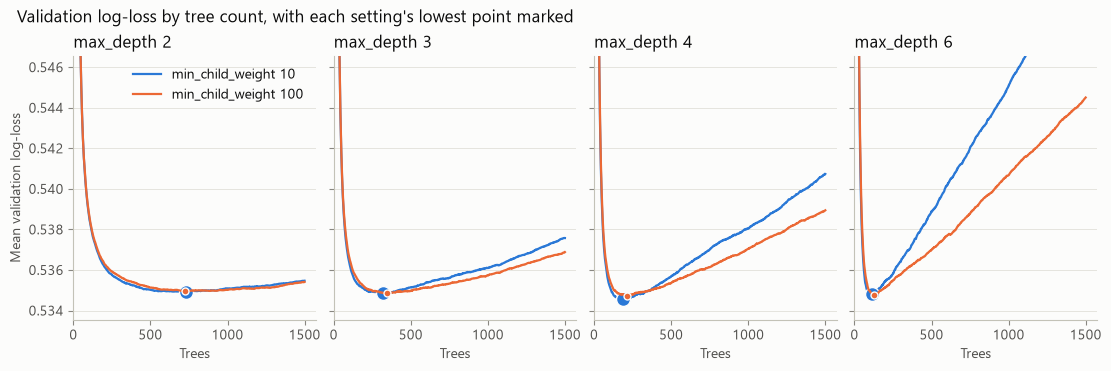

In [5]:
lowest = min(curve.mean(axis=0).min() for curve in curves_by_setting.values())
depths = sorted({depth for depth, _ in curves_by_setting})
figure, axes = plt.subplots(1, len(depths), figsize=(11, 3.6), sharey=True, layout="constrained")
for axis, depth in zip(axes, depths):
    for weight, color, marker_size in ((10, BLUE, 10), (100, ORANGE, 5)):
        mean_curve = curves_by_setting[(depth, weight)].mean(axis=0)
        trees = best_tree_count(curves_by_setting[(depth, weight)])
        axis.plot(np.arange(1, len(mean_curve) + 1), mean_curve, color=color, label=f"min_child_weight {weight}")
        axis.plot(trees, mean_curve[trees - 1], "o", color=color, markersize=marker_size, markeredgecolor=SURFACE, markeredgewidth=1)
    axis.set_title(f"max_depth {depth}")
    axis.set_xlabel("Trees")
    axis.set_xlim(left=0)
axes[0].set_ylim(lowest - 0.001, lowest + 0.012)
axes[0].set_ylabel("Mean validation log-loss")
axes[0].legend(loc="upper right")
figure.suptitle("Validation log-loss by tree count, with each setting's lowest point marked", x=0.01, ha="left", fontsize=12)
figure.savefig(FIGURES / "response_tuning_curves.png", dpi=160)
plt.show()

## 4. Performance

The chosen setting trains in each fold at its locked tree count, then scores that fold's validation rows. These out-of-fold scores are held in memory, for Phase 4's match assertion and for the checks below.

The baseline predicts each training fold's purchase rate for its validation fold. Intervals are stratified percentile bootstraps with 2,000 resamples and seed 42, using the same resamples for the model and the baseline. They capture uncertainty from the evaluation sample, not from refitting the models.

The baseline's interval is almost zero-width by construction. Stratifying on `target` fixes the number of buyers and non-buyers in every resample, and the baseline gives each group nearly the same loss in every fold. That width says nothing about how precisely the baseline is known.

In [6]:
phase3_m1_scores = np.full(len(y), np.nan)
baseline_scores = np.full(len(y), np.nan)
fold_models = {}
fold_rows = []
for fold in FOLDS:
    train, validation = fold_of_row != fold, fold_of_row == fold
    model = XGBClassifier(n_estimators=TREE_COUNT, **FIXED_SETTINGS, **CHOSEN_SETTINGS)
    model.fit(X[train], y[train])
    phase3_m1_scores[validation] = model.predict_proba(X[validation])[:, 1]
    baseline_scores[validation] = y[train].mean()
    fold_models[fold] = model
    fold_rows.append(
        {
            "fold": fold,
            "customers": int(validation.sum()),
            "purchase_rate": y[validation].mean(),
            "auc": roc_auc_score(y[validation], phase3_m1_scores[validation]),
            "log_loss": log_loss(y[validation], phase3_m1_scores[validation]),
            "baseline_log_loss": log_loss(y[validation], baseline_scores[validation]),
        }
    )
assert not np.isnan(phase3_m1_scores).any()

fold_metrics = pd.DataFrame(fold_rows)
# A fit at the locked count must reproduce the tuning curve. The tolerance is tight enough to catch one tree too many or too few.
assert np.allclose(fold_metrics["log_loss"], chosen_row[FOLD_COLUMNS].to_numpy(dtype=float), rtol=0, atol=1e-8)
fold_metrics.to_csv(TABLES / "response_fold_metrics.csv", index=False)
fold_metrics.round(5)

,fold,customers,purchase_rate,auc,log_loss,baseline_log_loss
0,1,15998,0.63652,0.77881,0.53517,0.65540
1,2,15997,0.63649,0.77806,0.53597,0.65541
2,3,15997,0.63649,0.78643,0.52814,0.65541
3,4,15997,0.63649,0.78361,0.53214,0.65541
4,5,15996,0.63653,0.77380,0.54134,0.65539


In [7]:
def row_log_loss(labels, scores):
    assert ((scores > 0) & (scores < 1)).all(), "Scores must lie strictly between 0 and 1"
    return -(labels * np.log(scores) + (1 - labels) * np.log(1 - scores))


model_losses = row_log_loss(y, phase3_m1_scores)
baseline_losses = row_log_loss(y, baseline_scores)
_, levels = np.unique(phase3_m1_scores, return_inverse=True)
n_levels = levels.max() + 1
positives, negatives = np.flatnonzero(y == 1), np.flatnonzero(y == 0)

rng = np.random.default_rng(SEED)
bootstrap = np.empty((BOOTSTRAP_RESAMPLES, 3))
for resample in range(BOOTSTRAP_RESAMPLES):
    sampled_positives = rng.choice(positives, size=len(positives))
    sampled_negatives = rng.choice(negatives, size=len(negatives))
    sampled = np.concatenate((sampled_positives, sampled_negatives))
    bootstrap[resample] = (
        auc_from_counts(
            np.bincount(levels[sampled_positives], minlength=n_levels),
            np.bincount(levels[sampled_negatives], minlength=n_levels),
        ),
        model_losses[sampled].mean(),
        baseline_losses[sampled].mean(),
    )

overall_auc = roc_auc_score(y, phase3_m1_scores)
overall_log_loss = log_loss(y, phase3_m1_scores)
overall_baseline_log_loss = log_loss(y, baseline_scores)
assert np.isclose(overall_log_loss, model_losses.mean()) and np.isclose(overall_baseline_log_loss, baseline_losses.mean())
assert np.isclose(overall_auc, auc_from_counts(np.bincount(levels[positives], minlength=n_levels), np.bincount(levels[negatives], minlength=n_levels)))


def metric_row(name, value, samples):
    low, high = np.percentile(samples, [2.5, 97.5])
    return {"metric": name, "value": value, "ci_low": low, "ci_high": high}


metrics = pd.DataFrame(
    [
        metric_row("AUC", overall_auc, bootstrap[:, 0]),
        metric_row("Log-loss", overall_log_loss, bootstrap[:, 1]),
        metric_row("Baseline log-loss", overall_baseline_log_loss, bootstrap[:, 2]),
        metric_row("Log-loss minus baseline", overall_log_loss - overall_baseline_log_loss, bootstrap[:, 1] - bootstrap[:, 2]),
    ]
)
metrics.to_csv(TABLES / "response_metrics.csv", index=False)
metrics.round(5)

,metric,value,ci_low,ci_high
0,AUC,0.78008,0.77691,0.78322
1,Log-loss,0.53455,0.53168,0.53746
2,Baseline log-loss,0.65540,0.65540,0.65540
3,Log-loss minus baseline,-0.12085,-0.12372,-0.11794


## 5. Calibration

Ten equal-count bins of the out-of-fold scores, plus a slope and intercept fitted together by logistic regression of `target` on the logit of the score. A flag is reported and the work proceeds without recalibrating, unless the project owner decides otherwise. Recalibrating would not change the response ranking, but it would change `tau(X) = m1(X) - m0(X)`.

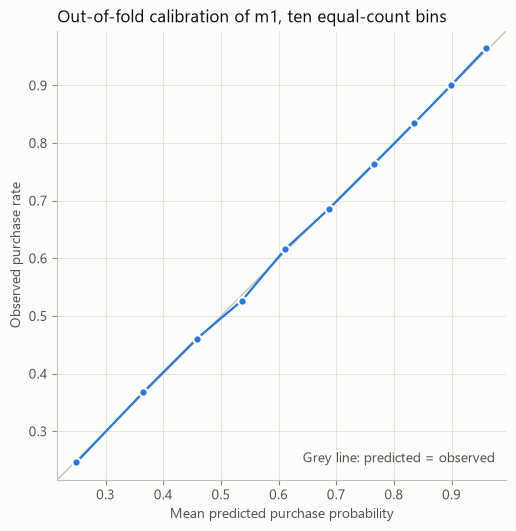

Slope 1.0067, intercept -0.0036


,bin,customers,mean_predicted,observed_rate,gap_points
0,1,7999,0.2493,0.2463,-0.3059
1,2,7998,0.3656,0.3681,0.2475
2,3,7999,0.4580,0.4604,0.2390
3,4,7998,0.5364,0.5268,-0.9602
4,5,7999,0.6116,0.6162,0.4641
5,6,7998,0.6867,0.6853,-0.1453
6,7,7998,0.7646,0.7629,-0.1642
7,8,7999,0.8353,0.8344,-0.0917
8,9,7998,0.8989,0.8998,0.0959
9,10,7999,0.9605,0.9649,0.4346


In [8]:
def calibration_report(labels, scores):
    assert ((scores > 0) & (scores < 1)).all(), "Scores must lie strictly between 0 and 1"
    bins = pd.qcut(pd.Series(scores).rank(method="first"), 10, labels=False) + 1
    table = (
        pd.DataFrame({"bin": bins, "label": labels, "score": scores})
        .groupby("bin")
        .agg(customers=("label", "size"), mean_predicted=("score", "mean"), observed_rate=("label", "mean"))
        .reset_index()
    )
    table["gap_points"] = (table["observed_rate"] - table["mean_predicted"]) * 100
    fit = sm.Logit(labels, sm.add_constant(np.log(scores / (1 - scores)))).fit(disp=0)
    return table, float(fit.params[0]), float(fit.params[1])


calibration, calibration_intercept, calibration_slope = calibration_report(y, phase3_m1_scores)
calibration.to_csv(TABLES / "response_calibration.csv", index=False)
pd.DataFrame([{"intercept": calibration_intercept, "slope": calibration_slope}]).to_csv(TABLES / "response_calibration_summary.csv", index=False)

figure, axis = plt.subplots(figsize=(5.6, 5.2), layout="constrained")
limits = (calibration[["mean_predicted", "observed_rate"]].min().min() - 0.03, calibration[["mean_predicted", "observed_rate"]].max().max() + 0.03)
axis.plot(limits, limits, color=AXIS, linewidth=1)
axis.text(limits[1] - 0.02, limits[0] + 0.03, "Grey line: predicted = observed", ha="right", color=INK_SECONDARY)
axis.plot(calibration["mean_predicted"], calibration["observed_rate"], "-o", color=BLUE, markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
axis.set_xlim(limits)
axis.set_ylim(limits)
axis.set_aspect("equal")
axis.grid(True, axis="both")
axis.set_xlabel("Mean predicted purchase probability")
axis.set_ylabel("Observed purchase rate")
axis.set_title("Out-of-fold calibration of m1, ten equal-count bins")
figure.savefig(FIGURES / "response_calibration.png", dpi=160)
plt.show()

print(f"Slope {calibration_slope:.4f}, intercept {calibration_intercept:.4f}")
calibration.round(4)

## 6. Leakage review

Gain share is each feature's share of total gain in each fold model, averaged across the five models. Single-feature AUC is `max(AUC, 1 - AUC)`, leaving out rows where the feature is null. Strong recency effects are expected and do not show leakage on their own.

In [9]:
def gain_shares(model):
    gains = model.get_booster().get_score(importance_type="total_gain")
    values = np.array([gains.get(f"f{j}", 0.0) for j in range(len(FEATURE_NAMES))])
    assert values.sum() > 0
    return values / values.sum()


def single_feature_auc(values):
    present = ~np.isnan(values)
    auc = roc_auc_score(y[present], values[present])
    return max(auc, 1 - auc)


shares_by_fold = np.array([gain_shares(fold_models[fold]) for fold in FOLDS])
importance = pd.DataFrame(
    {
        "feature": FEATURE_NAMES,
        "gain_share": shares_by_fold.mean(axis=0),
        "lowest_fold_share": shares_by_fold.min(axis=0),
        "highest_fold_share": shares_by_fold.max(axis=0),
        "single_feature_auc": [single_feature_auc(X[:, j]) for j in range(len(FEATURE_NAMES))],
    }
).sort_values("gain_share", ascending=False)
importance.to_csv(TABLES / "response_feature_importance.csv", index=False)
importance.round(4)

,feature,gain_share,lowest_fold_share,highest_fold_share,single_feature_auc
6,txn_count_60d,0.2779,0.2609,0.2924,0.7552
8,active_days_hist,0.1664,0.1420,0.1858,0.7517
5,txn_count_30d,0.1621,0.1525,0.1770,0.7486
9,avg_gap_days,0.0827,0.0778,0.0891,0.7392
0,days_since_last_purchase,0.0771,0.0690,0.0823,0.6996
7,txn_count_90d,0.0567,0.0404,0.0736,0.7527
4,txn_count_14d,0.0268,0.0247,0.0307,0.7240
32,age,0.0179,0.0162,0.0195,0.5417
3,txn_count_7d,0.0148,0.0132,0.0175,0.6984
2,txn_count_hist,0.0136,0.0088,0.0191,0.7498


### Purchase rate by recency

This check is descriptive and has no automatic rule. A smooth decline looks like habit, while a sharp jump at 0 or 1 days would suggest the undocumented outcome window overlaps the end of the purchase history. The project owner reviews it before Phase 4. The shaded band is a 95% Wald interval.

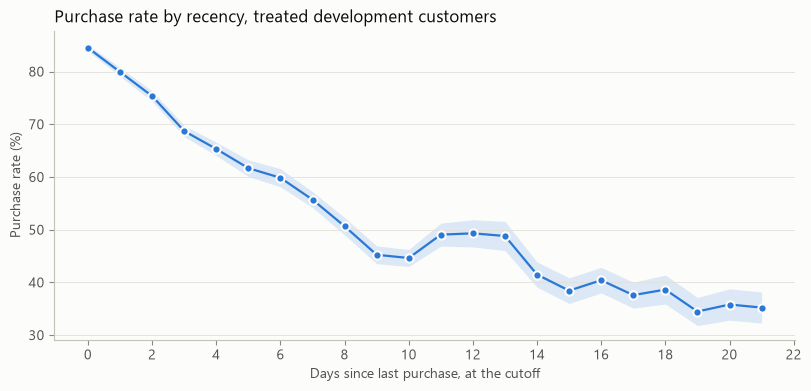

,days_since_last_purchase,customers,purchase_rate,ci_low,ci_high
0,0,14165,0.8450,0.8390,0.8509
1,1,8752,0.7992,0.7909,0.8076
2,2,7423,0.7535,0.7437,0.7633
3,3,7335,0.6871,0.6765,0.6977
4,4,5429,0.6532,0.6405,0.6658
5,5,3650,0.6167,0.6009,0.6325
6,6,3113,0.5985,0.5812,0.6157
7,7,4187,0.5570,0.5419,0.5720
8,8,3585,0.5066,0.4902,0.5229
9,9,3307,0.4524,0.4354,0.4693


In [10]:
recency = (
    customers.groupby("days_since_last_purchase")["target"]
    .agg(customers="size", purchase_rate="mean")
    .reset_index()
)
assert recency["days_since_last_purchase"].between(0, 22).all() and recency["customers"].sum() == len(y)
margin = 1.96 * np.sqrt(recency["purchase_rate"] * (1 - recency["purchase_rate"]) / recency["customers"])
recency["ci_low"], recency["ci_high"] = recency["purchase_rate"] - margin, recency["purchase_rate"] + margin
recency.to_csv(TABLES / "response_recency.csv", index=False)

figure, axis = plt.subplots(figsize=(8, 3.8), layout="constrained")
axis.fill_between(recency["days_since_last_purchase"], recency["ci_low"] * 100, recency["ci_high"] * 100, color=BLUE, alpha=0.15, linewidth=0)
axis.plot(recency["days_since_last_purchase"], recency["purchase_rate"] * 100, "-o", color=BLUE, markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
axis.set_xlabel("Days since last purchase, at the cutoff")
axis.set_ylabel("Purchase rate (%)")
axis.set_xticks(range(0, 23, 2))
axis.set_title("Purchase rate by recency, treated development customers")
figure.savefig(FIGURES / "response_recency.png", dpi=160)
plt.show()

recency.round(4)

## 7. Applying the committed rules

Every table above is written first, so a stop still leaves its evidence on disk. The locked setup file is written only if no stop rule triggers. Calibration flags do not stop the notebook.

In [11]:
largest_gain = importance.iloc[0]
largest_single_auc = importance.sort_values("single_feature_auc", ascending=False).iloc[0]
largest_bin_gap = calibration["gap_points"].abs().max()

decision = pd.DataFrame(
    [
        ("Log-loss below baseline", f"{overall_log_loss:.5f} vs {overall_baseline_log_loss:.5f}", "Stop if not below", overall_log_loss >= overall_baseline_log_loss, "Stop"),
        (f"Largest gain share ({largest_gain['feature']})", f"{largest_gain['gain_share']:.4f}", f">= {GAIN_STOP}", largest_gain["gain_share"] >= GAIN_STOP, "Stop"),
        (f"Largest single-feature AUC ({largest_single_auc['feature']})", f"{largest_single_auc['single_feature_auc']:.4f}", f">= {SINGLE_FEATURE_AUC_STOP}", largest_single_auc["single_feature_auc"] >= SINGLE_FEATURE_AUC_STOP, "Stop"),
        ("Overall out-of-fold AUC", f"{overall_auc:.4f}", f">= {OVERALL_AUC_STOP}", overall_auc >= OVERALL_AUC_STOP, "Stop"),
        ("Calibration slope", f"{calibration_slope:.4f}", f"Outside {SLOPE_RANGE[0]} to {SLOPE_RANGE[1]}", not SLOPE_RANGE[0] <= calibration_slope <= SLOPE_RANGE[1], "Report and proceed"),
        ("Largest calibration bin gap (points)", f"{largest_bin_gap:.2f}", f"> {BIN_GAP_FLAG_POINTS}", largest_bin_gap > BIN_GAP_FLAG_POINTS, "Report and proceed"),
    ],
    columns=["check", "measured", "threshold", "triggered", "action_if_triggered"],
)
decision.to_csv(TABLES / "response_decision.csv", index=False)
display(decision)

stops = decision[decision["triggered"] & (decision["action_if_triggered"] == "Stop")]
if len(stops):
    raise RuntimeError("Stop and investigate before Phase 4: " + "; ".join(stops["check"]))
setup = {**FIXED_SETTINGS, **CHOSEN_SETTINGS, "n_estimators": TREE_COUNT}
pd.Series(setup, name="value").rename_axis("setting").reset_index().to_csv(TABLES / "response_model_setup.csv", index=False)
print("No stop rule triggered. Locked setup:", setup)

,check,measured,threshold,triggered,action_if_triggered
0,Log-loss below baseline,0.53455 vs 0.65540,Stop if not below,False,Stop
1,Largest gain share (txn_count_60d),0.2779,>= 0.5,False,Stop
2,Largest single-feature AUC (txn_count_60d),0.7552,>= 0.8,False,Stop
3,Overall out-of-fold AUC,0.7801,>= 0.9,False,Stop
4,Calibration slope,1.0067,Outside 0.9 to 1.1,False,Report and proceed
5,Largest calibration bin gap (points),0.96,> 2.0,False,Report and proceed


No stop rule triggered. Locked setup: {'objective': 'binary:logistic', 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'tree_method': 'hist', 'random_state': 42, 'reg_lambda': 1, 'reg_alpha': 0, 'gamma': 0, 'n_jobs': 8, 'max_depth': 4, 'min_child_weight': 10, 'n_estimators': 185}


### Measurements quoted in the documents

The conclusion below and `reports/decisions.md` quote these values, so a change must stop the run.

In [12]:
assert CHOSEN_SETTINGS == {"max_depth": 4, "min_child_weight": 10} and TREE_COUNT == 185
assert tuning["eligible"].sum() == 1 and tuning.loc[tuning["eligible"], "best"].all()
assert tuning["tree_cap_used"].eq(FIRST_TREE_CAP).all()
assert tuning[["max_depth", "min_child_weight", "tree_count"]].to_numpy().tolist() == [
    [2, 10, 730], [2, 100, 726], [3, 10, 320], [3, 100, 345], [4, 10, 185], [4, 100, 214], [6, 10, 113], [6, 100, 126],
]
assert tuning["mean_log_loss"].round(5).tolist() == [0.53492, 0.53496, 0.53485, 0.53485, 0.53455, 0.53473, 0.53480, 0.53477]
assert metrics[["value", "ci_low", "ci_high"]].round(4).to_numpy().tolist() == [
    [0.7801, 0.7769, 0.7832],
    [0.5346, 0.5317, 0.5375],
    [0.6554, 0.6554, 0.6554],
    [-0.1209, -0.1237, -0.1179],
]
assert round(calibration_slope, 4) == 1.0067 and round(calibration_intercept, 4) == -0.0036
assert round(largest_bin_gap, 2) == 0.96
assert (largest_gain["feature"], round(largest_gain["gain_share"], 4)) == ("txn_count_60d", 0.2779)
assert (largest_single_auc["feature"], round(largest_single_auc["single_feature_auc"], 4)) == ("txn_count_60d", 0.7552)
assert recency["days_since_last_purchase"].tolist() == list(range(22))
quoted_days = recency.set_index("days_since_last_purchase").loc[[0, 1, 2, 3, 10, 11, 12, 13, 14]]
assert quoted_days["customers"].tolist() == [14_165, 8_752, 7_423, 7_335, 3_666, 2_016, 1_448, 1_254, 1_632]
assert (quoted_days["purchase_rate"] * 100).round(1).tolist() == [84.5, 79.9, 75.3, 68.7, 44.6, 49.1, 49.3, 48.8, 41.5]
assert (quoted_days["ci_low"] * 100).round(1).tolist() == [83.9, 79.1, 74.4, 67.7, 43.0, 46.9, 46.7, 46.0, 39.1]
assert (quoted_days["ci_high"] * 100).round(1).tolist() == [85.1, 80.8, 76.3, 69.8, 46.2, 51.2, 51.9, 51.6, 43.9]
assert tuning["mean_difference"].round(5).tolist() == [0.00037, 0.00041, 0.00030, 0.00030, 0.0, 0.00018, 0.00025, 0.00022]
assert tuning["se_difference"].round(5).tolist() == [0.00012, 0.00014, 0.00011, 0.00014, 0.0, 0.00015, 0.00019, 0.00016]
assert (round(fold_metrics["auc"].min(), 4), round(fold_metrics["auc"].max(), 4)) == (0.7738, 0.7864)
express = importance[importance["feature"].str.startswith("express_")]
assert (round(express["gain_share"].max(), 4), round(express["single_feature_auc"].max(), 4)) == (0.0079, 0.5144)
assert calibration.loc[calibration["gap_points"].abs().idxmax(), "bin"] == 4
tenth_bin = calibration[calibration["bin"] == 10].iloc[0]
assert (round(tenth_bin["mean_predicted"] * 100, 1), round(tenth_bin["observed_rate"] * 100, 1)) == (96.1, 96.5)
print("All quoted values match")

All quoted values match


## Phase 3 conclusion

All values are **Measured** on out-of-fold predictions for the 79,985 treated development customers.

- **Locked setup:** `max_depth` 4, `min_child_weight` 10 and 185 trees, with the fixed settings in `outputs/tables/response_model_setup.csv`. It was the only setting within one standard error of the best, because it was the best. The eight settings differ by at most 0.0004 in mean log-loss.
- **Performance:** AUC 0.7801 (95% CI 0.7769 to 0.7832) and log-loss 0.5346 (0.5317 to 0.5375), against a baseline log-loss of 0.6554.
- **Calibration:** slope 1.0067, intercept -0.0036, largest bin gap 0.96 points. Neither flag was raised, so nothing was recalibrated.
- **Leakage thresholds:** none reached. The largest gain share and single-feature AUC are both `txn_count_60d`, at 0.2779 and 0.7552, and overall AUC is below 0.90.
- **Recency:** the purchase rate falls from 84.5% at 0 days through 79.9%, 75.3% and 68.7% at 3 days, with no sharp jump at 0 or 1 days. An unexplained step up at 11 to 13 days is about 49%, against 44.6% at 10 days and 41.5% at 14 days. No treated development customer has a value of 22.

**What this does not show:** these metrics describe how well the model predicts purchase among treated customers. They say nothing about whether the SMS changed anyone's behaviour, which Phases 4 and 5 address.